# SGS

A função `bcb.sgs.get` obtém os dados do webservice do Banco Central, interface JSON do serviço BCData/SGS -[Sistema Gerenciador de Séries Temporais (SGS)](https://www3.bcb.gov.br/sgspub/localizarseries/localizarSeries.do?method=prepararTelaLocalizarSeries).

Os parâmetros `start` e `end` aceitam strings `YYYY-MM-DD`, `datetime.date`, `datetime.datetime` ou `bcb.utils.Date`. Também é possível usar `last` para buscar os últimos `n` pontos disponíveis.

## Timeout em consultas longas

Por padrão, as requisições usam o timeout global do cliente HTTP compartilhado. Para consultas SGS com janelas grandes ou respostas lentas, informe `timeout` na chamada. O valor é aplicado por tentativa HTTP; quando houver retry, cada tentativa usa o mesmo timeout.

``` python
from bcb import sgs

df = sgs.get(11, start="1990-01-01", end="2026-01-01", timeout=120)
raw = sgs.get_json(11, start="1990-01-01", timeout=120)
```

Se a consulta continuar lenta mesmo com timeout maior, divida o período em janelas menores e concatene os resultados.

## Formato tidy no SGS

Por padrão, `bcb.sgs.get` retorna um DataFrame no formato largo. Para retornar uma tabela longa, use `tidy=True`. Nesse modo, o DataFrame tem as colunas `Date`, `series` e `value`. A coluna `series` usa o nome informado em `codes`; quando nenhum nome é informado, usa o código numérico da série.

In [1]:
from bcb import sgs
sgs.get({'SELIC': 11, 'IPCA': 433}, start='2024-01-01', tidy=True).head()

,Date,series,value
0,2024-01-02,SELIC,0.043739
1,2024-01-03,SELIC,0.043739
2,2024-01-04,SELIC,0.043739
3,2024-01-05,SELIC,0.043739
4,2024-01-08,SELIC,0.043739


O parâmetro `tidy` só afeta o retorno `output='dataframe'`. Quando `output='text'` é usado, a função continua retornando o JSON bruto.

## Exemplos

In [2]:
from bcb import sgs
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.style.use('bmh')

df = sgs.get({'IPCA': 433}, start='2002-02-01')
df.index = df.index.to_period('M')
df.head()

,IPCA
Date,
2002-02,0.36
2002-03,0.60
2002-04,0.80
2002-05,0.21
2002-06,0.42


In [3]:
dfr = df.rolling(12)
i12 = dfr.apply(lambda x: (1 + x/100).prod() - 1).dropna() * 100
i12.head()

,IPCA
Date,
2003-01,14.467041
2003-02,15.847124
2003-03,16.572608
2003-04,16.769209
2003-05,17.235307


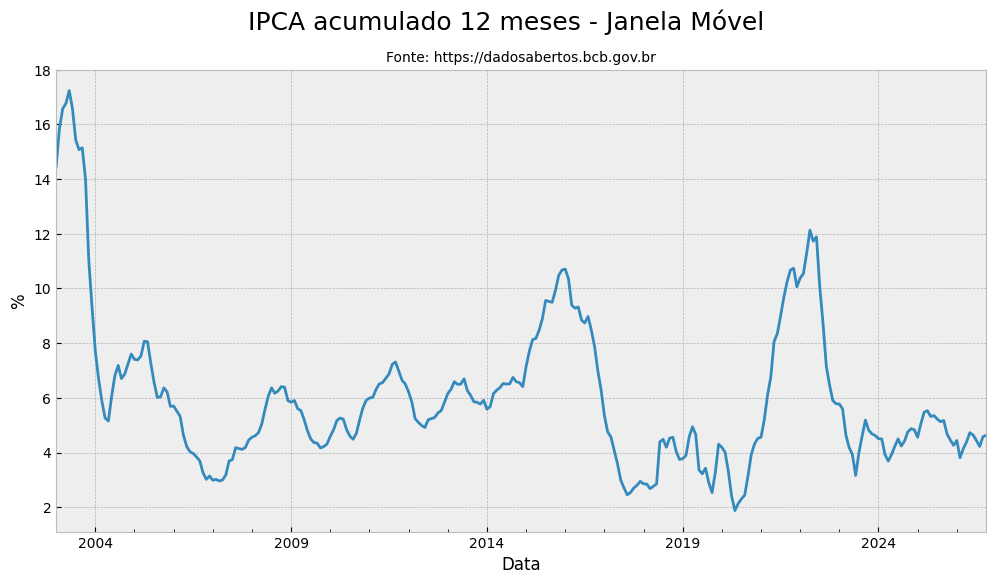

In [4]:
i12.plot(figsize=(12,6))
plt.title('Fonte: https://dadosabertos.bcb.gov.br', fontsize=10)
plt.suptitle('IPCA acumulado 12 meses - Janela Móvel', fontsize=18)
plt.xlabel('Data')
plt.ylabel('%')
plt.legend().set_visible(False)

## Obtendo o JSON bruto

A função `bcb.sgs.get_json` retorna o JSON bruto da API para um único código. Para pipelines de dados onde o dado bruto deve ser persistido antes de qualquer transformação, o parâmetro `output='text'` pode ser passado à função `bcb.sgs.get`.

Para um único código é retornada uma `str`; para múltiplos códigos é retornado um `dict` mapeando código inteiro → JSON string.

``` python
from bcb import sgs

# único código → str
raw = sgs.get(433, start='2024-01-01', output='text')

# múltiplos códigos → dict[int, str]
raws = sgs.get([433, 189], start='2024-01-01', output='text')
# raws[433] → JSON string do IPCA
# raws[189] → JSON string do IGP-M

# salvar em disco
with open('ipca_raw.json', 'w') as f:
    f.write(raw)
```

O JSON retornado é um array de objetos com os campos `data` e `valor`, exatamente como devolvido pela API BCData/SGS. O comportamento padrão (retorno de DataFrame) é mantido quando o parâmetro não é informado.

# Dados de Inadimplência de Operações de Crédito

Os modos aceitos são `PF` (pessoas físicas), `PJ` (pessoas jurídicas) e `total`; `all` é aceito como alias de `total`. Os locais devem ser todos estados ou todos regiões, sem misturar os dois tipos na mesma chamada.

In [5]:
from bcb.sgs.regional_economy import get_non_performing_loans
from bcb.utils import BRAZILIAN_REGIONS, BRAZILIAN_STATES
import pandas as pd
get_non_performing_loans(["RR"], last=10, mode="all")

,RR
Date,
2025-12-01,5.17
2026-01-01,5.50
2026-02-01,5.74
2026-03-01,5.58
2026-04-01,6.03
2026-05-01,6.33
2026-06-01,6.05
2026-07-01,6.25
2026-08-01,6.57


In [6]:
northeast_states = BRAZILIAN_REGIONS["NE"]
get_non_performing_loans(northeast_states, last=5, mode="pj")

,AL,BA,CE,MA,PB,PE,PI,RN,SE
Date,,,,,,,,,
2026-05-01,3.55,3.37,3.87,6.63,9.09,3.77,2.89,4.17,4.79
2026-06-01,3.50,3.28,3.55,6.60,8.91,3.65,2.76,4.16,4.38
2026-07-01,3.71,3.40,3.58,7.19,8.20,3.80,2.73,4.34,4.43
2026-08-01,3.89,3.45,3.60,7.28,8.17,3.85,2.91,4.39,4.31
2026-09-01,3.90,3.66,3.50,6.58,8.06,3.76,2.79,4.30,4.68


In [7]:
get_non_performing_loans(BRAZILIAN_STATES, mode="PF", start="2024-01-01")

,AC,AP,AM,PA,RO,RR,TO,AL,BA,CE,...,GO,MT,MS,ES,MG,RJ,SP,PR,RS,SC
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-01,3.49,4.09,5.40,4.16,2.76,3.84,2.63,4.64,4.68,4.74,...,3.14,2.11,2.90,3.21,3.09,5.33,3.45,2.76,2.48,2.85
2024-02-01,3.48,4.05,5.25,4.15,2.78,3.84,2.76,4.60,4.64,4.68,...,3.14,2.14,2.89,3.25,3.13,5.25,3.43,2.75,2.51,2.84
2024-03-01,3.43,4.01,5.18,4.09,2.81,3.88,2.78,4.58,4.57,4.69,...,3.16,2.16,2.94,3.21,3.10,5.17,3.36,2.74,2.53,2.81
2024-04-01,3.46,4.10,5.15,4.09,2.85,3.84,2.78,4.59,4.59,4.70,...,3.18,2.22,2.95,3.19,3.11,5.13,3.41,2.75,2.53,2.81
2024-05-01,3.54,4.22,5.26,4.15,2.99,3.91,2.97,4.68,4.58,4.75,...,3.23,2.31,3.07,3.18,3.16,5.14,3.46,2.83,2.60,2.87
2024-06-01,3.50,4.11,5.14,4.09,3.07,3.91,2.88,4.62,4.51,4.61,...,3.16,2.30,3.09,3.06,3.09,5.04,3.40,2.76,2.61,2.79
2024-07-01,3.49,4.13,5.14,4.14,3.16,3.90,3.12,4.63,4.52,4.58,...,3.44,2.58,3.69,3.04,3.11,5.02,3.43,2.87,2.61,2.82
2024-08-01,3.41,4.03,5.05,4.13,3.23,3.82,3.42,4.60,4.45,4.47,...,3.78,2.89,4.10,3.00,3.16,4.97,3.42,3.02,2.58,2.81
2024-09-01,3.55,4.06,4.99,4.16,3.24,3.92,3.56,4.57,4.39,4.42,...,3.75,2.91,4.10,2.96,3.16,4.90,3.39,3.01,2.54,2.79
